In [117]:
import torch
import torchaudio
import torchaudio.functional as F
import torchaudio.transforms as T
import matplotlib.pyplot as plt
from torch.utils.data import Dataset, DataLoader
from sklearn.cluster import MiniBatchKMeans
import seaborn as sns
import math

import sys
import os

sys.path.append(os.path.join(os.getcwd(), "WavTokenizer"))
from decoder.pretrained import WavTokenizer # type: ignore

In [82]:
libritts_data = torchaudio.datasets.LIBRITTS('data', url="dev-clean", download=True)

In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

sample_rate = 24000
n_centroids = 2**12

n_fft = 512
win_length = 480
hop_length = None
n_mels = 80
duration = 20
frame_size = 24000 * duration/1000

size = libritts_data.__len__()
sample = libritts_data.__getitem__(42)
print(size)
print(sample)

5736
(tensor([[-7.0190e-04,  9.1553e-05, -8.8501e-04,  ...,  7.3242e-04,
         -1.2207e-03, -3.0518e-05]]), 24000, 'They agreed that it did, but no one could explain the mystery.', 'They agreed that it did, but no one could explain the mystery.', 1272, 135031, '1272_135031_000054_000000')


/home/enzo/vincent/wavtokenizer_test/.venv/lib/python3.12/site-packages/torchaudio/_backend/utils.py:213: UserWarning: In 2.9, this function's implementation will be changed to use torchaudio.load_with_torchcodec` under the hood. Some parameters like ``normalize``, ``format``, ``buffer_size``, and ``backend`` will be ignored. We recommend that you port your code to rely directly on TorchCodec's decoder instead: https://docs.pytorch.org/torchcodec/stable/generated/torchcodec.decoders.AudioDecoder.html#torchcodec.decoders.AudioDecoder.
  warnings.warn(
/home/enzo/vincent/wavtokenizer_test/.venv/lib/python3.12/site-packages/torchaudio/_backend/ffmpeg.py:88: UserWarning: torio.io._streaming_media_decoder.StreamingMediaDecoder has been deprecated. This deprecation is part of a large refactoring effort to transition TorchAudio into a maintenance phase. The decoding and encoding capabilities of PyTorch for both audio and video are being consolidated into TorchCodec. Please see https://github.

In [84]:
mel_spectrogram = T.MelSpectrogram(
    sample_rate=sample_rate,
    n_fft=n_fft,
    win_length=win_length,
    hop_length=hop_length,
    center=True,
    pad_mode="reflect",
    power=2.0,
    norm="slaney",
    n_mels=n_mels,
    mel_scale="htk",
)

amplitude_to_db = T.AmplitudeToDB()

In [85]:
sample_audio = sample[0][0,0:480].unsqueeze(0)
melspec = mel_spectrogram(sample_audio)
print(melspec.shape)
print(sample_audio.shape)

torch.Size([1, 80, 3])
torch.Size([1, 480])


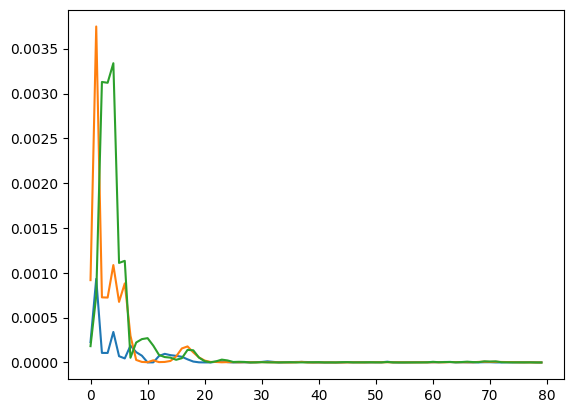

In [86]:
plt.plot(melspec[0,:,:])

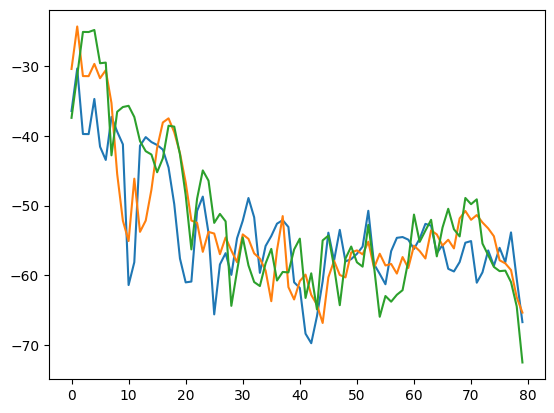

In [87]:
plt.plot(amplitude_to_db(melspec[0,:,:]))

In [88]:
class ChunkedTimeDataset(Dataset):
    def __init__(self, base_dataset, duration=20, sample_rate=24000):
        self.dataset = []
        self.frame_size = int(sample_rate * duration / 1000)

        for i in range(len(base_dataset)):
            wav, *_ = base_dataset[i]
            wav_size = wav.shape[1]
            for start in range(0, wav_size - self.frame_size + 1, self.frame_size):
                sub_wav = wav[0, start : start + self.frame_size]
                self.dataset.append(sub_wav)
                    
    def __len__(self):
        return len(self.dataset)
    
    def __getitem__(self, index):
        return self.dataset[index]

In [89]:
dataset = ChunkedTimeDataset(libritts_data, duration, sample_rate)
dataset.__len__()

1612969

In [90]:
dataset[0].shape

torch.Size([480])

In [ ]:
mel_spectrogram = T.MelSpectrogram(
    sample_rate=24000,
    n_fft=n_fft,
    win_length=win_length,
    hop_length=hop_length, 
    center=True,
    pad_mode="reflect",
    power=2.0,
    norm="slaney",
    n_mels=n_mels,
    mel_scale="htk",
).to(device)

amplitude_to_db = T.AmplitudeToDB().to(device)

dataloader = DataLoader(dataset, batch_size=4096, shuffle=False)

In [92]:
all_melspec_db = []
all_melspec = []

with torch.no_grad():
    for batch in dataloader:
        batch = batch.to(device)

        melspec = mel_spectrogram(batch)
        melspec_db = amplitude_to_db(melspec[:,:,1])

        all_melspec.append(melspec[:,:,1].cpu())
        all_melspec_db.append(melspec_db.cpu())

mel_dataset = torch.cat(all_melspec, dim=0)
mel_db_dataset = torch.cat(all_melspec_db, dim=0)

In [93]:
mel_db_dataset.shape

torch.Size([1612969, 80])

In [94]:
mel_dataset.shape

torch.Size([1612969, 80])

In [ ]:
kmeans = MiniBatchKMeans(n_clusters=n_centroids)
kmeans = kmeans.fit(mel_dataset)
kmeans_db = MiniBatchKMeans(n_clusters=n_centroids)
kmeans_db = kmeans_db.fit(mel_db_dataset)

In [96]:
centroids = torch.Tensor(kmeans.cluster_centers_)
print(centroids)
centroids_db = torch.Tensor(kmeans_db.cluster_centers_)
print(centroids_db)
print(centroids_db.shape)

tensor([[2.4048e-06, 9.8119e-06, 5.1556e-06,  ..., 1.8478e-07, 1.2234e-07,
         8.4593e-08],
        [7.6682e-03, 3.1287e-02, 8.4993e-04,  ..., 2.2640e-06, 1.0828e-06,
         9.7574e-07],
        [1.0654e-02, 4.3468e-02, 7.4592e-03,  ..., 1.5449e-04, 2.7406e-04,
         1.4050e-04],
        ...,
        [5.3612e-05, 2.1874e-04, 1.8522e-04,  ..., 6.8965e-08, 5.0290e-08,
         1.8671e-08],
        [5.9148e-04, 2.4133e-03, 1.3692e-03,  ..., 3.2703e-06, 1.1417e-06,
         8.0592e-07],
        [1.1465e-02, 4.6777e-02, 3.2437e-01,  ..., 1.7211e-06, 6.8560e-07,
         7.3582e-07]])
tensor([[-44.8573, -38.7506, -40.7114,  ..., -47.9590, -48.7092, -51.7756],
        [-34.6020, -28.4953, -30.1192,  ..., -57.1913, -59.7571, -63.6770],
        [-49.4037, -43.2970, -39.6572,  ..., -62.7178, -63.4649, -64.2641],
        ...,
        [-66.4069, -60.3084, -56.9659,  ..., -33.1714, -35.4032, -38.4400],
        [-47.2130, -41.1063, -43.6088,  ..., -55.5920, -56.3307, -59.2502],
        [-6

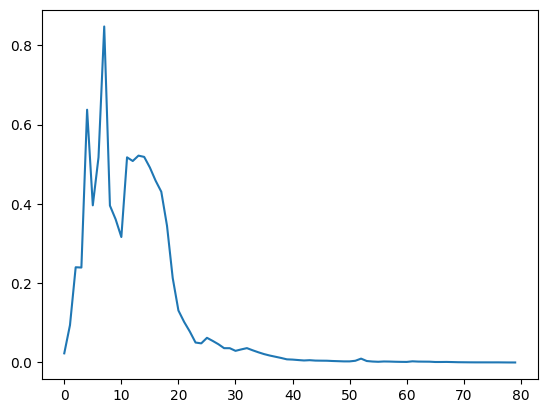

In [97]:
m = torch.mean(centroids, dim=0)
plt.plot(m.cpu())

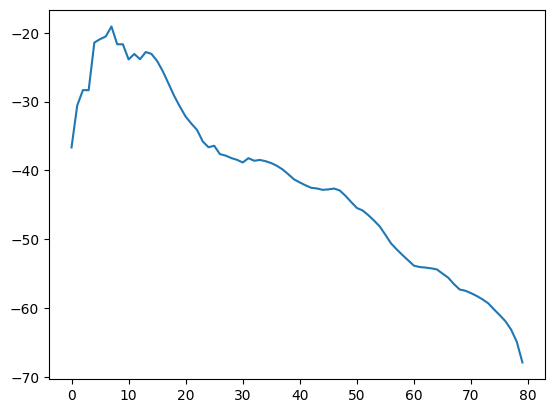

In [98]:
m = torch.mean(centroids_db, dim=0)
plt.plot(m.cpu())

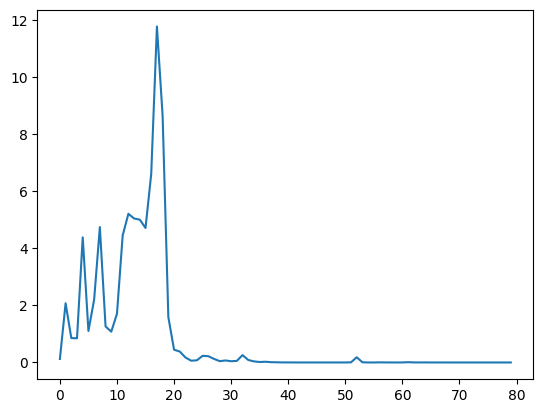

In [99]:
v = torch.var(centroids, dim=0)
plt.plot(v.cpu())

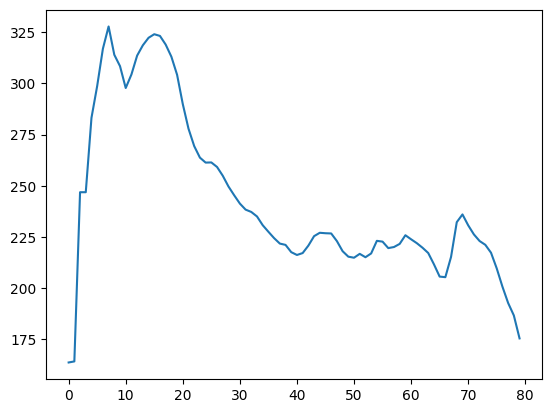

In [100]:
v = torch.var(centroids_db, dim=0)
plt.plot(v.cpu())

In [101]:
config_path = "./WavTokenizer/configs/wavtokenizer_smalldata_frame40_3s_nq1_code4096_dim512_kmeans200_attn.yaml"
model_path = "./WavTokenizer/WavTokenizer_small_600_24k_4096.ckpt"

wavtokenizer = WavTokenizer.from_pretrained0802(config_path, model_path)
wavtokenizer = wavtokenizer.to(device)

/home/enzo/vincent/wavtokenizer_test/.venv/lib/python3.12/site-packages/torch/nn/utils/weight_norm.py:144: FutureWarning: `torch.nn.utils.weight_norm` is deprecated in favor of `torch.nn.utils.parametrizations.weight_norm`.
  WeightNorm.apply(module, name, dim)


In [102]:
wavtokenizer

WavTokenizer(
  (feature_extractor): EncodecFeatures(
    (encodec): EncodecModel(
      (encoder): SEANetEncoder(
        (model): Sequential(
          (0): SConv1d(
            (conv): NormConv1d(
              (conv): Conv1d(1, 32, kernel_size=(7,), stride=(1,))
              (norm): Identity()
            )
          )
          (1): SEANetResnetBlock(
            (block): Sequential(
              (0): ELU(alpha=1.0)
              (1): SConv1d(
                (conv): NormConv1d(
                  (conv): Conv1d(32, 16, kernel_size=(3,), stride=(1,))
                  (norm): Identity()
                )
              )
              (2): ELU(alpha=1.0)
              (3): SConv1d(
                (conv): NormConv1d(
                  (conv): Conv1d(16, 32, kernel_size=(1,), stride=(1,))
                  (norm): Identity()
                )
              )
            )
            (shortcut): SConv1d(
              (conv): NormConv1d(
                (conv): Conv1d(32, 32, kerne

In [103]:
tmp=[vq.codebook for vq in wavtokenizer.feature_extractor.encodec.quantizer.vq.layers]
wavtokenizer_codebook = tmp[0]
print(wavtokenizer_codebook.shape)

torch.Size([4096, 512])


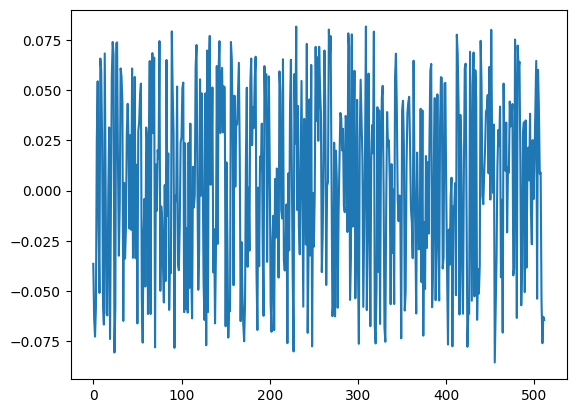

In [104]:
m = torch.mean(wavtokenizer_codebook, dim=0)
plt.plot(m.cpu())

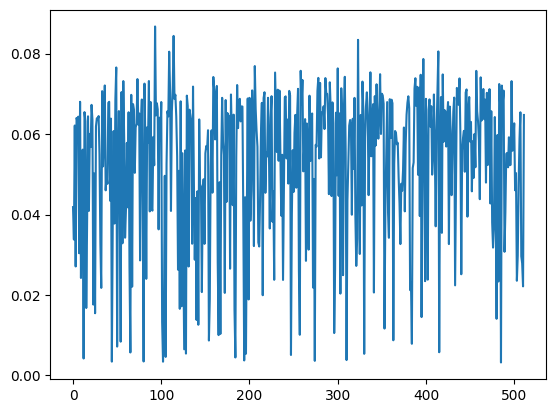

In [105]:
v = torch.var(wavtokenizer_codebook, dim=0)
plt.plot(v.cpu())

In [106]:
def correlation(X,Y):
    X_centered = X - X.mean(dim=0).unsqueeze(0)
    Y_centered = Y - Y.mean(dim=0).unsqueeze(0)
    
    X_normalized = X_centered / (X_centered.norm(dim=0).unsqueeze(0) + 1e-8)
    Y_normalized = Y_centered / (Y_centered.norm(dim=0).unsqueeze(0) + 1e-8)
    
    return torch.matmul(X_normalized.transpose(0,1), Y_normalized)

In [107]:
centroids = centroids.to(device)
centroids_db = centroids_db.to(device)
wavtokenizer_codebook = wavtokenizer_codebook.to(device)

corr_mel_wav = correlation(centroids, wavtokenizer_codebook).cpu()
corr_mel_db_wav = correlation(centroids_db, wavtokenizer_codebook).cpu()

In [108]:
print(corr_mel_wav)
print(corr_mel_db_wav)

tensor([[-0.0390,  0.0211, -0.0266,  ..., -0.0138, -0.0032, -0.0355],
        [-0.0390,  0.0211, -0.0266,  ..., -0.0138, -0.0032, -0.0355],
        [-0.0327, -0.0038, -0.0226,  ..., -0.0299, -0.0350, -0.0317],
        ...,
        [ 0.0075,  0.0035,  0.0019,  ...,  0.0045,  0.0130,  0.0018],
        [ 0.0105,  0.0039,  0.0013,  ...,  0.0075,  0.0208,  0.0045],
        [ 0.0140, -0.0178, -0.0250,  ..., -0.0180,  0.0285, -0.0106]])
tensor([[ 0.0059, -0.0037,  0.0034,  ...,  0.0013, -0.0004,  0.0052],
        [ 0.0058, -0.0038,  0.0033,  ...,  0.0012, -0.0004,  0.0051],
        [ 0.0083, -0.0034,  0.0172,  ...,  0.0162, -0.0051,  0.0237],
        ...,
        [-0.0230,  0.0095, -0.0072,  ...,  0.0011, -0.0092, -0.0066],
        [-0.0240,  0.0103, -0.0086,  ...,  0.0002, -0.0083, -0.0084],
        [-0.0240,  0.0092, -0.0109,  ..., -0.0020, -0.0076, -0.0103]])


<Axes: >

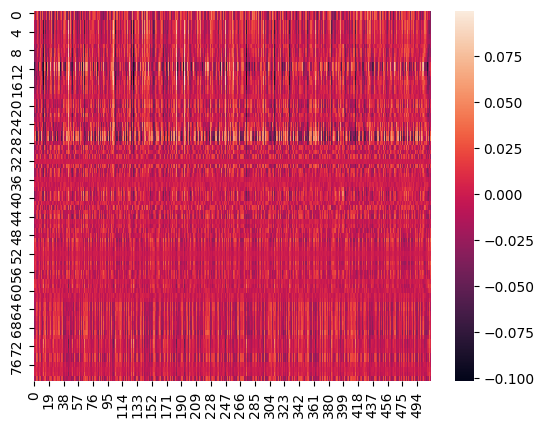

In [109]:
sns.heatmap(corr_mel_wav)

<Axes: >

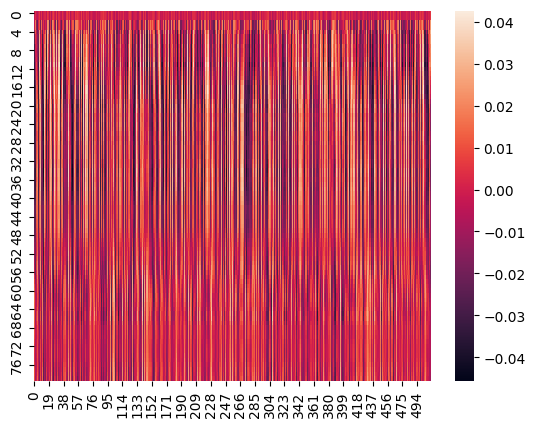

In [110]:
sns.heatmap(corr_mel_db_wav)

In [111]:
audio_path = "data/a.wav"
wav_a, sr_a = torchaudio.load(audio_path)
melspec_a = mel_spectrogram(wav_a.to(device))
print(melspec.shape)
print(wav_a.shape)

torch.Size([3241, 80, 3])
torch.Size([1, 48000])


/home/enzo/vincent/wavtokenizer_test/.venv/lib/python3.12/site-packages/torchaudio/_backend/utils.py:213: UserWarning: In 2.9, this function's implementation will be changed to use torchaudio.load_with_torchcodec` under the hood. Some parameters like ``normalize``, ``format``, ``buffer_size``, and ``backend`` will be ignored. We recommend that you port your code to rely directly on TorchCodec's decoder instead: https://docs.pytorch.org/torchcodec/stable/generated/torchcodec.decoders.AudioDecoder.html#torchcodec.decoders.AudioDecoder.
  warnings.warn(
/home/enzo/vincent/wavtokenizer_test/.venv/lib/python3.12/site-packages/torchaudio/_backend/ffmpeg.py:88: UserWarning: torio.io._streaming_media_decoder.StreamingMediaDecoder has been deprecated. This deprecation is part of a large refactoring effort to transition TorchAudio into a maintenance phase. The decoding and encoding capabilities of PyTorch for both audio and video are being consolidated into TorchCodec. Please see https://github.

In [125]:
chunck_a = ChunkedTimeDataset(wav_a.unsqueeze(0).unsqueeze(0))
all_melspec_db = []
all_melspec = []

for i in range(len(chunck_a)):
    melspec = mel_spectrogram(chunck_a[i].to(device))
    melspec_db = amplitude_to_db(melspec[:,1])
    all_melspec.append(melspec[:,1].cpu())
    all_melspec_db.append(melspec_db.cpu())

sequence = torch.stack(all_melspec, dim=0)
sequence_db = torch.stack(all_melspec_db, dim=0)

In [126]:
kmeans.predict(sequence)

array([2050, 2050,  793, 2050, 2050, 2050, 2050,  793, 2050, 2050, 2050,
       2050,  793, 2050, 2050, 2050, 2050,  793, 2050, 2050, 2050, 2050,
        793, 2050, 2050, 2050, 2050,  793, 2050, 2050, 2050, 2050,  793,
       2050, 2050, 2050, 2050,  793, 2050, 2050, 2050, 2050,  793, 2050,
       2050, 2050, 2050,  793, 2050, 2050, 2050, 2050,  793, 2050, 2050,
       2050, 2050,  793, 2050, 2050, 2050, 2050,  793, 2050, 2050, 2050,
       2050,  793, 2050, 2050, 2050, 2050,  793, 2050, 2050, 2050, 2050,
        793, 2050, 2050, 2050, 2050,  793, 2050, 2050, 2050, 2050,  793,
       2050, 2050, 2050, 2050,  793, 2050, 2050, 2050, 2050,  793, 2050,
       2050], dtype=int32)

In [127]:
kmeans_db.predict(sequence_db)

array([3283, 2341, 2341, 2341, 3283, 3283, 2341, 2341, 2341, 3283, 3283,
       2341, 2341, 2341, 3283, 3283, 2341, 2341, 2341, 3283, 3283, 2341,
       2341, 2341, 3283, 3283, 2341, 2341, 2341, 3283, 3283, 2341, 2341,
       2341, 3283, 3283, 2341, 2341, 2341, 3283, 3283, 2341, 2341, 2341,
       3283, 3283, 2341, 2341, 2341, 3283, 3283, 2341, 2341, 2341, 3283,
       3283, 2341, 2341, 2341, 3283, 3283, 2341, 2341, 2341, 3283, 3283,
       2341, 2341, 2341, 3283, 3283, 2341, 2341, 2341, 3283, 3283, 2341,
       2341, 2341, 3283, 3283, 2341, 2341, 2341, 3283, 3283, 2341, 2341,
       2341, 3283, 3283, 2341, 2341, 2341, 3283, 3283, 2341, 2341, 2341,
       3283], dtype=int32)